# Champion and challenger: a paired Brier bootstrap and grade disagreement


**Question:** Does a challenger model measurably beat the champion once its Brier difference is paired obligor by obligor, and how many obligors would it move to another grade?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic; notebook 03 of topic 01 for the lights
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- say why a validator compares the model in use (the champion) with a simpler or different model (the challenger) on the same rows, and what SS1/23 and the ECB guide ask of that comparison;
- compute the Brier difference with a **paired** bootstrap interval, explain why pairing matters, and read its light;
- measure how many obligors change grade by two or more notches between the two models;
- read the committed challenger comparison of case C02 (a scorecard champion against five challengers on Polish companies), rebuild its Brier rows with the engine, and say what a gain in discrimination does and does not justify.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Put the pipeline on the import path for the master scale, import the packages and print their versions
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.generators.scores import LogisticPortfolio
from riskvalidation.ml import challenger as ch
from riskvalidation.ml.challenger import PairedBrier
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import ml as vml
from scipy import special

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.core.calibration import MASTER_SCALE_UPPER

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
YN = {True: "yes", False: "no"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

- **A logistic portfolio of the engine** (`riskvalidation.generators.scores.LogisticPortfolio`): 4,000 obligors with three correlated covariates, a true PD that is logistic in them (`pd_true`) and a model PD (`pd`) that the generator distorts by a calibration slope and intercept we choose. The champion is that distorted model; the challengers are the true PD and a deliberately optimistic version of it. Synthetic, generated from a seed, no licence class.
- **The master scale** of the pipeline (`pipeline.core.calibration`): twelve grades whose upper bounds grow by a factor 1.5 from 1%. It is the same reader topic 01 uses.
- **The committed challenger comparison of case C02** (`data/derived/C02/h2.json`; owner: this repository, derived from the UCI Polish bankruptcy data, CC BY 4.0, class mirror-allowed): the horizon of two years, a locked stratified holdout of 2,938 companies with 155 bankruptcies, a scorecard as the champion (rung P1) and five challengers (an L1 logistic, a piecewise-linear tree logistic, an EBM and two boosted-tree models). The pipeline fitted the models; this notebook reads its comparison rows and prints the engine version that baked them.

In [2]:
# Open the committed comparison and print the engine that baked it, the split and the champion
path = ROOT / "data" / "derived" / "C02" / "h2.json"
h2 = json.loads(path.read_text(encoding="utf-8"))
split = h2["outputs"]["split"]
print("baked with riskvalidation", h2["provenance"]["riskvalidation_version"])
print(
    "protocol:",
    split["protocol"],
    "| holdout rows",
    split["holdout_rows"],
    "| holdout events",
    split["holdout_events"],
)
print(
    "champion:",
    h2["outputs"]["challenger"][0]["champion"],
    "| challengers:",
    len(h2["outputs"]["challenger"]),
)

baked with riskvalidation 1.0.1
protocol: locked-stratified-holdout | holdout rows 2938 | holdout events 155
champion: h2-P1-scorecard | challengers: 5


## Method

SS1/23 asks for challenger comparisons (principle 3.3(b)(iii)), and the ECB guide asks that a model's complexity be justified by a performance gain over a simpler benchmark such as a generalised linear model (paragraph 60). The engine offers three readings of "how different, and how much better".

### Step 1: the Brier difference with a paired bootstrap

The Brier score is the mean squared error of a probability, $B = \frac{1}{n}\sum_i (p_i - y_i)^2$, which rewards calibration and sharpness together (a different question from the AUC, which only ranks). For the champion $p^{cm}$ and a challenger $p^{ch}$ scored on the **same obligors**, define the per-obligor difference and the Brier difference (challenger minus champion; negative is better for the challenger):

$$d_i = (p^{ch}_i - y_i)^2 - (p^{cm}_i - y_i)^2, \qquad \Delta B = \frac{1}{n}\sum_{i=1}^{n} d_i .$$

The interval resamples the **obligors** $B$ times with replacement, jointly for both models (the same resampled indices score both), takes $\Delta B^{(b)}$ for each resample and reports the 2.5th and 97.5th percentiles. Resampling jointly keeps the pairing: the champion and the challenger make errors on the same obligors, which are correlated, and the variance of the difference is smaller than the sum of the two variances. The engine's earlier `bootstrap_ci` resamples one score and cannot do this. The light is amber when the whole interval lies **above** zero (the challenger is measurably worse than the champion) and green otherwise; a better challenger is never a finding against the champion, and the test has no policy threshold.

The next cell draws the portfolio and prints the Brier score of the champion, of the true PD and of an optimistic challenger (the true PD lowered by 0.8 in log-odds).

In [3]:
# Draw 4,000 obligors: the champion is the distorted model PD, the challengers the true PD and an optimistic one
portfolio = LogisticPortfolio(n=4000, intercept=-2.0, calibration_slope=0.5, calibration_intercept=-0.3)
draw = portfolio.draw(np.random.default_rng(1))
y = draw["defaults"]
champion = draw["pd"]
better = draw["pd_true"]
optimistic = special.expit(special.logit(better) - 0.8)
forecasts = (
    ("champion (distorted)", champion),
    ("challenger, true PD", better),
    ("challenger, optimistic", optimistic),
)
for label, p in forecasts:
    auc = float(disc.disc_auc(p, y).metric)
    print(f"{label:24s} Brier {np.mean((p - y) ** 2):.5f} | mean PD {p.mean():.4f} | AUC {auc:.4f}")
print("observed default rate:", round(float(y.mean()), 4))

champion (distorted)     Brier 0.12789 | mean PD 0.2296 | AUC 0.7762
challenger, true PD      Brier 0.12234 | mean PD 0.1683 | AUC 0.7762
challenger, optimistic   Brier 0.13240 | mean PD 0.0926 | AUC 0.7762
observed default rate: 0.176


The two challengers have the same ranking as their base (a constant shift in log-odds does not change order), so the AUC cannot tell the optimistic challenger from the true PD; the Brier score can. The next cell runs the paired bootstrap with 1,000 resamples for both and calls the engine test, and then shows what pairing buys: the standard error of the Brier difference from the paired per-obligor differences against the one from treating the two Brier scores as independent.

In [4]:
# The paired bootstrap and the engine light for each challenger, then the standard error with and without pairing
results = {}
for label, p in (("true PD", better), ("optimistic", optimistic)):
    boot = ch.paired_brier_bootstrap(champion, p, y, n_boot=1000, seed=3)
    row = vml.challenger_brier("challenger", boot)
    results[label] = boot
    print(f"{label:14s} ΔBrier {boot.diff:+.5f} | 95% [{boot.lo:+.5f}, {boot.hi:+.5f}]", end=" ")
    print(f"| n_boot {boot.n_boot} | light {LIGHT[row.light.value]}")
d = (better - y) ** 2 - (champion - y) ** 2
paired_se = d.std(ddof=1) / np.sqrt(len(d))
var_new = ((better - y) ** 2).var(ddof=1)
var_old = ((champion - y) ** 2).var(ddof=1)
unpaired_se = np.sqrt(var_new + var_old) / np.sqrt(len(d))
print(f"standard error of the difference: paired {paired_se:.5f} | treated as independent {unpaired_se:.5f}")
same = ch.paired_brier_bootstrap(champion, champion, y, n_boot=200, seed=3)
print("identical forecasts:", same.diff, same.lo, same.hi)

true PD        ΔBrier -0.00555 | 95% [-0.00719, -0.00391] | n_boot 1000 | light green
optimistic     ΔBrier +0.00451 | 95% [+0.00137, +0.00768] | n_boot 1000 | light amber
standard error of the difference: paired 0.00086 | treated as independent 0.00449
identical forecasts: 0.0 0.0 0.0


The two intervals are the result of the paired bootstrap and the quickest way to read them is against zero. The next
cell draws each challenger's Brier difference with its 95% interval and a dashed line at no difference.

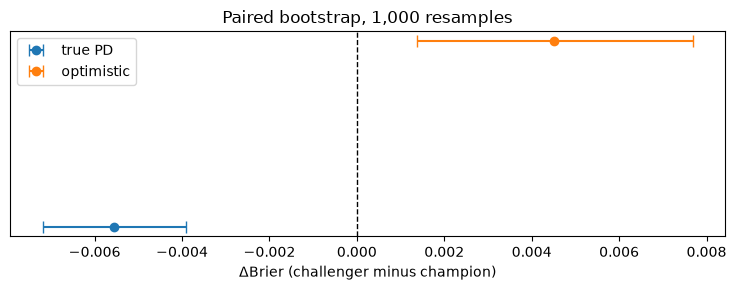

In [5]:
# Paired 95% intervals of the Brier difference of the two plant challengers
fig, ax = plt.subplots(figsize=(7.5, 3.0))
for k, (label, boot) in enumerate(results.items()):
    err = [[boot.diff - boot.lo], [boot.hi - boot.diff]]
    ax.errorbar(boot.diff, k, xerr=err, fmt="o", capsize=4, label=label)
ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
ax.set_yticks([])
ax.set_xlabel("ΔBrier (challenger minus champion)")
ax.set_title("Paired bootstrap, 1,000 resamples")
ax.legend()
fig.tight_layout()
plt.show()

The true-PD challenger sits wholly to the left of zero, from -0.00719 to -0.00391, so it is measurably better than the
champion and the light is green. The optimistic challenger sits wholly to the right, from +0.00137 to +0.00768, and the
light is amber. Both rank the obligors exactly like the champion (an AUC of 0.7762), so only calibration separates them,
and the intervals are tight because the champion and the challenger are resampled together: the standard error is 0.00086
paired against 0.00449 if the two scores were treated as independent.

### Step 2: grade disagreement

A challenger with a better Brier score can still assign other grades, and grades are what decisions and capital use. The engine counts the share of obligors whose grades under two PD vectors differ by at least $m$ notches (the dossier's rule uses 2):

$$\text{disagreement}_m = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\bigl[\, |g(p^{cm}_i) - g(p^{ch}_i)| \ge m \,\bigr], \qquad g(p) = \#\{\text{edges} \le p\}.$$

The measure is symmetric in the two models. The edges are the eleven interior upper bounds of the master scale. The next cell computes it for the three PD vectors at one and at two notches.

In [6]:
# Share of obligors whose grade differs by at least one and two notches, and the symmetry check
edges = np.array(MASTER_SCALE_UPPER[:-1])
print("interior edges:", len(edges))
for label, p in (("true PD", better), ("optimistic", optimistic)):
    one = ch.grade_disagreement(champion, p, edges, notches=1)
    two = ch.grade_disagreement(champion, p, edges, notches=2)
    print(f"{label:14s} 1 notch or more {one:.4f} | 2 notches or more {two:.4f}")
forward = ch.grade_disagreement(champion, better, edges)
backward = ch.grade_disagreement(better, champion, edges)
print("symmetric:", YN[forward == backward])

interior edges: 11
true PD        1 notch or more 0.8085 | 2 notches or more 0.4903
optimistic     1 notch or more 0.9768 | 2 notches or more 0.8520
symmetric: yes


### Step 3: the discrimination comparison (DeLong)

The paired test of two AUCs on the same rows is DeLong's (the engine's `disc_delong`). It takes both risk vectors and the outcomes and returns the AUC of each, their difference, the variance of the difference and a two-sided p-value. It can only compare rankings that differ: the champion and the true PD of the plant have the same ranking (the distortion is monotone), so the variance of the difference is zero and the engine returns `not_evaluated` instead of a number. The Brier comparison of step 1 is the one that sees the calibration. To have a different ranking, the next cell adds a third forecast, a simpler benchmark that uses only the first covariate (the kind of generalised linear benchmark the ECB guide has in mind), and runs DeLong against both.

In [7]:
# DeLong test of the champion against the true PD and against a simpler benchmark on the first covariate
simple = special.expit(-2.0 + 0.8 * draw["x"][:, 0])
brier_champion = np.mean((champion - y) ** 2)
for label, p in (("true PD", better), ("simple benchmark", simple)):
    t = disc.disc_delong(p, champion, y)
    z = "nan" if t.p_value is None else f"{t.statistic:.3f}"
    pv = "-" if t.p_value is None else f"{t.p_value:.3g}"
    print(f"{label:18s} AUC challenger {t.extras['auc_1']:.4f} champion {t.extras['auc_2']:.4f}", end=" ")
    print(
        f"| variance of the difference {t.extras['variance']:.3e} | z {z} | p {pv} | light {LIGHT[t.light.value]}"
    )
    print(
        f"{'':18s} Brier challenger {np.mean((p - y) ** 2):.5f} against the champion's {brier_champion:.5f}"
    )

true PD            AUC challenger 0.7762 champion 0.7762 | variance of the difference 0.000e+00 | z nan | p - | light not evaluated
                   Brier challenger 0.12234 against the champion's 0.12789
simple benchmark   AUC challenger 0.7374 champion 0.7762 | variance of the difference 3.562e-05 | z -6.501 | p 7.99e-11 | light red
                   Brier challenger 0.13105 against the champion's 0.12789


### Step 4: the committed comparison of case C02

For each of the five challengers the pipeline wrote a DeLong row and a paired-Brier row. The next cell rebuilds the engine's `PairedBrier` from the committed difference and interval, calls the engine's test and compares its light with the committed one. It prints the AUC difference with its DeLong p-value, the Brier difference with its interval and the grade disagreement, for every challenger.

In [8]:
# Rebuild the paired-Brier object of each committed challenger and call the engine test
committed = {t["model_id"]: t for t in h2["tests"] if t["test_id"] == "ml.challenger_brier"}
print(f"{'challenger':16s} {'ΔAUC':>8s} {'p DeLong':>10s} {'ΔBrier':>9s}", end=" ")
print(f"{'95% interval':>22s} {'grades ≥2':>11s} light")
for row in h2["outputs"]["challenger"]:
    b = row["brier_diff_ci"]
    paired = PairedBrier(row["brier_diff"], b["lo"], b["hi"], 1000)
    again = vml.challenger_brier(row["challenger"], paired)
    old = committed[row["challenger"]]
    print(f"{row['challenger']:16s} {row['auc_diff']:8.4f} {row['delong_p_value']:10.2e}", end=" ")
    print(f"{row['brier_diff']:9.5f} [{b['lo']:+.5f}, {b['hi']:+.5f}]", end=" ")
    print(f"{row['grade_disagreement_share']:11.4f} {LIGHT[again.light.value]} ({LIGHT[old['light']]})")

challenger           ΔAUC   p DeLong    ΔBrier           95% interval   grades ≥2 light
h2-P2a-l1          0.0248   1.52e-04  -0.00077 [-0.00183, +0.00027]      0.1290 green (green)
h2-P2b-pltr        0.0936   6.46e-11  -0.01066 [-0.01399, -0.00739]      0.5000 green (green)
h2-P3-ebm          0.1117   1.24e-14  -0.01714 [-0.02075, -0.01382]      0.5000 green (green)
h2-P4-lightgbm     0.1128   6.26e-16  -0.01507 [-0.01901, -0.01142]      0.4952 green (green)
h2-P4-xgboost      0.1023   3.79e-14  -0.01280 [-0.01664, -0.00891]      0.4973 green (green)


Five challengers and three measures are easier to compare on one plane. The next cell places each committed challenger
by its AUC gain and its Brier gain over the scorecard and labels it with the share of obligors it moves by two grades
or more.

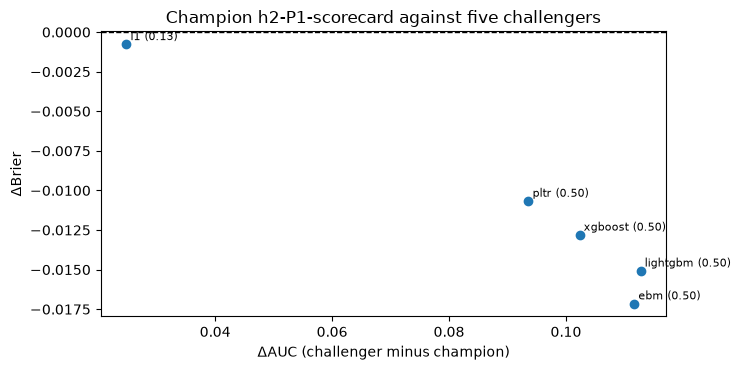

In [9]:
# Committed challengers: AUC gain against Brier gain, labelled by the share that change two grades
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for row in h2["outputs"]["challenger"]:
    ax.scatter(row["auc_diff"], row["brier_diff"], color="tab:blue")
    name = f"{row['challenger'].split('-')[-1]} ({row['grade_disagreement_share']:.2f})"
    point = (row["auc_diff"], row["brier_diff"])
    ax.annotate(name, point, fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("ΔAUC (challenger minus champion)")
ax.set_ylabel("ΔBrier")
ax.set_title("Champion h2-P1-scorecard against five challengers")
fig.tight_layout()
plt.show()

Every point lies to the right of zero in AUC, from +0.0248 for the L1 logistic to +0.1128 for LightGBM, and below zero in
Brier. The L1 logistic (P2a) is the exception worth noting: it is the closest to the origin, its Brier interval from
-0.00183 to +0.00027 contains zero, and only 0.1290 of its obligors change two grades. The four more complex models gain
between 0.01066 and 0.01714 of Brier and move about half of the obligors (0.4952 to 0.5000), which is what a business
owner pays for the extra complexity.

## Results

**Answer:** Yes for ranking, and for calibration in four of the five committed challengers, but the gain has a price in grades. On the plant the true PD improves the Brier score by 0.00555 (interval from -0.00719 to -0.00391, green) and the optimistic challenger worsens it by 0.00451 (amber), although their AUC is the same 0.7762; pairing narrows the standard error from 0.00449 to 0.00086. In the committed C02 comparison every challenger raises the AUC, by +0.0248 to +0.1128, the L1 logistic's Brier interval from -0.00183 to +0.00027 contains zero, and the other four move 0.4952 to 0.5000 of the obligors by two grades or more.

- **A better AUC and a better Brier are different findings.** The three forecasts of the plant rank the obligors in the same order (AUC 0.7762 for all), so DeLong cannot compare the champion with the true PD: the variance of the difference is zero and the engine returns `not_evaluated` instead of a number. The Brier score does separate them: the true PD improves on the distorted champion by 0.00555 (interval from -0.00719 to -0.00391, green), and the optimistic challenger, whose ranking is the same, is worse by 0.00451 (interval from +0.00137 to +0.00768, amber), because the whole interval lies above zero.
- **Pairing is what makes the interval narrow.** The standard error of the Brier difference is 0.00086 with the paired per-obligor differences and 0.00449 if the two Brier scores are treated as independent: five times larger, wide enough to hide the improvement of the true PD. Identical forecasts give a difference of 0 and an interval of zero width.
- **A model can differ in grade without differing in rank.** The true PD puts 49.03% of the obligors two grades or more away from the champion (80.85% one or more), and the optimistic challenger 85.20% (97.68% one or more). Neither changes the AUC. The measure is symmetric, and it is the one that tells a business owner how many decisions would move.
- **A simpler benchmark is read the same way.** The benchmark with one covariate ranks worse (AUC 0.7374 against 0.7762, z = -6.501, p = 7.99e-11, red in the engine's DeLong light) and its Brier is also higher (0.13105 against 0.12789).
- **The committed comparison of C02 separates what a gain justifies.** All five challengers have a higher AUC than the scorecard (from +0.0248 to +0.1128, every DeLong p-value below 2e-4) and a green paired-Brier light. But the L1 logistic's Brier interval, from -0.00183 to +0.00027, contains zero: its discrimination gain does not come with a measurable calibration gain, and 12.90% of the obligors change two grades or more. The other four have intervals entirely below zero (from -0.01066 for the piecewise tree logistic to -0.01714 for the EBM) and about half of the obligors (from 49.52% to 50.00%) change two grades or more. The engine rebuilt from the committed intervals gives the committed light for the five rows; all were baked with riskvalidation 1.0.1.

What the results do not show: the plant is synthetic and its champion is distorted on purpose; a green Brier light says that the challenger is not measurably worse, not that it should replace the champion; ECB paragraph 60 asks that complexity be justified by a performance gain, and the size of the gain that justifies it is a judgement of the validator, not a threshold of the engine.

## Summary

- The Brier difference between a challenger and the champion is bootstrapped by resampling the obligors jointly for both models; the pairing makes the interval about five times narrower here, and the light is amber only when the whole interval lies above zero.
- Grade disagreement counts the obligors whose grades differ by at least two notches; a model can leave the AUC unchanged and move half the grades.
- DeLong compares two rankings and cannot compare two forecasts that rank alike; the Brier comparison sees calibration and the AUC comparison sees order.
- In the committed C02 comparison every challenger improves the AUC significantly, the L1 logistic does so without a measurable Brier gain, and about half the obligors change two grades under the four more complex models.
- The comparison supplies the evidence; whether the gain justifies the complexity (ECB paragraph 60, SS1/23) is the validator's judgement.

**What to try next.** Notebook 06 turns from performance to fairness: selection rates by group and the tests built on them.

## References

- Bank of England PRA (2023), SS1/23 Model risk management principles for banks, principle 3.3(b)(iii) on challenger comparisons. https://www.bankofengland.co.uk/prudential-regulation/publication/2023/may/model-risk-management-principles-for-banks-ss
- ECB (2025), Guide to internal models, the paragraphs on the randomness of the training process, overfitting, explainability and the justification of complexity (43, 59, 60, 62, 64 to 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Zieba, M., Tomczak, S. K. and Tomczak, J. M., Polish companies bankruptcy data, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- PiML-Toolbox (Apache-2.0), outcome tests WeakSpot, Overfit, Reliability, Robustness and Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox